# 06 — Storytelling: Cara Menjelaskan Project Ini dalam 8–10 Menit

**Kenapa notebook ini ada?** Pekerjaan data tidak selesai saat model jadi — selesai
ketika orang lain paham dan mau memakainya.

Notebook ini bukan analisis baru. Isinya **cara menceritakan** hasil notebook 01–05,
dengan pola yang sama seperti project sebelumnya:

> ## Hook → Angka → Makna → Rekomendasi
>
> 1. **Hook** — kalimat pembuka yang membuat orang mau mendengarkan
> 2. **Angka** — 1–2 bukti, bukan seluruh tabel
> 3. **Makna** — terjemahan angka ke bahasa manusia
> 4. **Rekomendasi** — apa yang bisa dilakukan pembaca

**Aturan emasnya:** setiap angka yang disebut harus bisa ditunjukkan sumbernya di
notebook 04 atau 05.

## 0. Persiapan

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)

BASE = Path.cwd()
if not (BASE / "data").exists():
    BASE = BASE.parent
print("root project:", BASE)

df = pd.read_csv(BASE / "data" / "clean" / "churn_clean.csv")
df["kelompok_tenure"] = pd.cut(
    df["tenure"], bins=[-1, 6, 12, 24, 48, 72],
    labels=["0-6 bln", "7-12 bln", "13-24 bln", "25-48 bln", "49-72 bln"],
)
print("data:", df.shape)

root project: C:\Users\53\Documents\data sains\machine learning\project ML Supervised
data: (7043, 21)


## 1. Cerita #1 — "Setengah pelanggan baru pergi dalam 6 bulan"

**Hook:** "Kalau Anda punya 100 pelanggan baru hari ini, tiga bulan lagi tinggal 70.
Enam bulan lagi, sebagian dari mereka sudah pindah ke kompetitor."

**Angka:** pelanggan dengan masa berlangganan 0–6 bulan punya churn rate **52,9%** —
dua kali lipat rata-rata keseluruhan (26,5%). Kelompok ini menyumbang **41,9%** dari
seluruh churn, padahal hanya 21% dari pelanggan.

**Makna:** masalahnya bukan pelanggan lama yang bosan, tapi **pelanggan baru yang
tidak pernah merasa betah**. Masa kritisnya ada di awal, bukan di akhir.

**Rekomendasi:** program onboarding 90 hari — kontak proaktif di minggu 1, 4, dan 12.

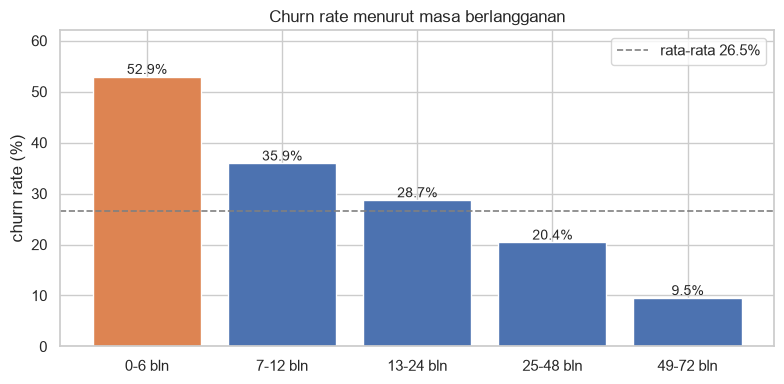

,jumlah,rate,porsi
kelompok_tenure,,,
0-6 bln,1481,52.9,41.9
7-12 bln,705,35.9,13.5
13-24 bln,1024,28.7,15.7
25-48 bln,1594,20.4,17.4
49-72 bln,2239,9.5,11.4


In [2]:
t = df.groupby("kelompok_tenure", observed=True)["Churn"].agg(jumlah="size", rate="mean")
t["rate"] = (t["rate"] * 100).round(1)
t["porsi"] = (df.groupby("kelompok_tenure", observed=True)["Churn"].sum()
              / df["Churn"].sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(t.index.astype(str), t["rate"], color=["#dd8452"] + ["#4c72b0"] * 4)
for b, v in zip(bars, t["rate"]):
    ax.annotate(f"{v:.1f}%", (b.get_x() + b.get_width() / 2, b.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.axhline(df["Churn"].mean() * 100, color="gray", ls="--", lw=1.2,
           label=f"rata-rata {df['Churn'].mean()*100:.1f}%")
ax.set_title("Churn rate menurut masa berlangganan")
ax.set_ylabel("churn rate (%)")
ax.set_ylim(0, 62)
ax.legend()
plt.tight_layout()
plt.show()
t

## 2. Cerita #2 — "Yang pergi justru yang bayar lebih mahal"

**Hook:** "Kalau ditanya kenapa pelanggan pergi, jawaban paling umum adalah 'kemahalan'.
Datanya bilang sebaliknya."

**Angka:** pelanggan yang pergi membayar rata-rata **$74,44/bulan**, sedangkan yang
bertahan **$61,27** — selisih 21% **lebih mahal**. Ditambah lagi, **88,6%** dari
seluruh churn berasal dari kontrak bulanan (churn rate 42,7% vs 2,8% untuk kontrak
2 tahun).

**Makna:** ini bukan masalah **harga**, tapi masalah **komitmen dan nilai**. Pelanggan
mau bayar mahal asal merasa dapat imbalan setara. Yang tidak merasa, pergi — dan
biasanya mereka yang terkunci tanpa kontrak.

**Rekomendasi:** jangan turunkan harga. Dorong **perpanjangan kontrak** untuk
pelanggan fiber optic yang masih bulanan — insentif 1 tahun lebih murah daripada
kehilangan pelanggan $74/bulan.

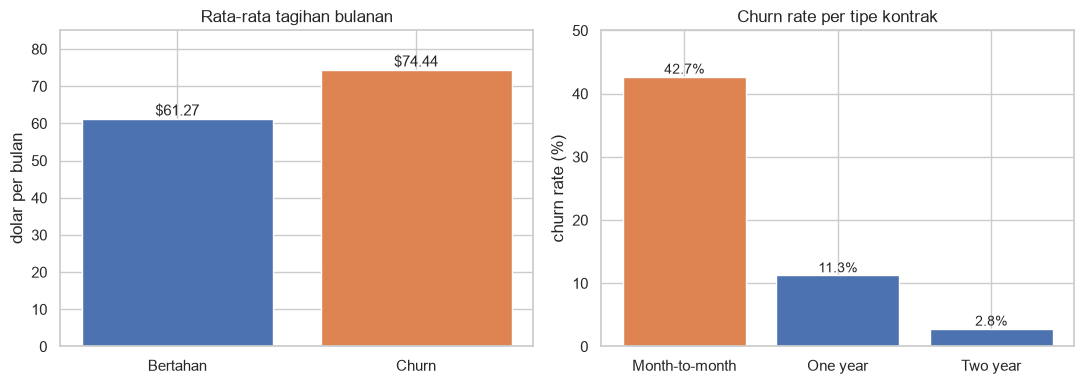

In [3]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))

rata = df.groupby("Churn")["MonthlyCharges"].mean()
a1.bar(["Bertahan", "Churn"], rata.values, color=["#4c72b0", "#dd8452"])
for i, v in enumerate(rata.values):
    a1.annotate(f"${v:.2f}", (i, v), ha="center", va="bottom", fontsize=11)
a1.set_title("Rata-rata tagihan bulanan")
a1.set_ylabel("dolar per bulan")
a1.set_ylim(0, 85)

t = df.groupby("Contract")["Churn"].mean().mul(100).sort_values(ascending=False)
a2.bar(t.index, t.values, color=["#dd8452", "#4c72b0", "#4c72b0"])
for i, v in enumerate(t.values):
    a2.annotate(f"{v:.1f}%", (i, v), ha="center", va="bottom", fontsize=10)
a2.set_title("Churn rate per tipe kontrak")
a2.set_ylabel("churn rate (%)")
a2.set_ylim(0, 50)

plt.tight_layout()
plt.show()

## 3. Cerita #3 — "Model mengalahkan aturan sederhana, tapi tidak sempurna"

**Hook:** "Sebelum percaya machine learning, saya uji dulu: apa bisa ditebak pakai
aturan biasa? Karena kalau iya, kita tidak butuh ML."

**Angka:** aturan sederhana — *kontrak bulanan + tenure ≤ 12 bulan + tanpa tech
support* — menandai 270 pelanggan dan menangkap **167** dari 374 yang benar-benar
churn (recall 44,7%). Model Random Forest menangkap **300** (recall 80,2%) dengan
AUC 0,845.

**Makna:** model menangkap **133 pelanggan lebih banyak**. Tapi model juga
menghasilkan lebih banyak alarm palsu (precision 52,4% vs 61,9%). Jadi model ini
layak dipakai **sebagai daftar prioritas**, bukan sebagai keputusan otomatis.

**Rekomendasi:** pakai skor model untuk mengurutkan pelanggan, lalu hubungi dari
skor tertinggi sampai kapasitas tim habis. Jangan pakai model untuk menolak layanan
ke pelanggan.

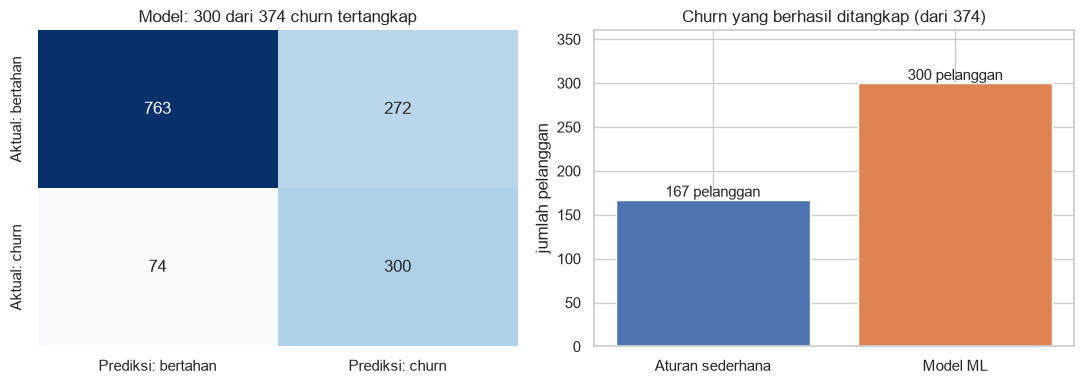

metrik model: {'recall': 0.802, 'precision': 0.524, 'f1': 0.634, 'auc': 0.845, 'accuracy': 0.754}


In [4]:
import joblib
from sklearn.metrics import confusion_matrix

model_data = joblib.load(BASE / "models" / "churn_model.joblib")
m = model_data["metrics"]
c = model_data["confusion"]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))

cm = np.array([[c["tn"], c["fp"]], [c["fn"], c["tp"]]])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a1,
            xticklabels=["Prediksi: bertahan", "Prediksi: churn"],
            yticklabels=["Aktual: bertahan", "Aktual: churn"])
a1.set_title("Model: 300 dari 374 churn tertangkap")

a2.bar(["Aturan sederhana", "Model ML"], [167, 300], color=["#4c72b0", "#dd8452"])
for i, v in enumerate([167, 300]):
    a2.annotate(f"{v} pelanggan", (i, v), ha="center", va="bottom", fontsize=11)
a2.set_title("Churn yang berhasil ditangkap (dari 374)")
a2.set_ylabel("jumlah pelanggan")
a2.set_ylim(0, 360)

plt.tight_layout()
plt.show()
print("metrik model:", m)

## 4. Naskah presentasi 8–10 menit

Bacakan ini sambil membuka notebook 01–05. Angka dalam kurung menunjukkan waktu.

---

**(0:00–0:40) Pembuka — masalah**

> "Perusahaan ini punya 7.043 pelanggan, dan 26,5% di antaranya sudah berhenti
> berlangganan. Mempertahankan pelanggan jauh lebih murah daripada mencari yang
> baru, jadi pertanyaan saya sederhana: **bisa tidak kita tahu siapa yang akan pergi
> sebelum dia benar-benar pergi?**"

---

**(0:40–1:40) Data & tantangan**

> "Datanya 21 kolom per pelanggan: profil, layanan, kontrak, tagihan. Yang menarik,
> tidak ada nilai kosong sama sekali — hanya satu kolom, `TotalCharges`, yang
> tersimpan sebagai teks dengan 11 nilai kosong. Semuanya pelanggan baru dengan
> tenure nol, jadi saya isi nol karena mereka memang belum pernah ditagih.
>
> Tantangan utamanya: kelasnya tidak seimbang, 26,5% versus 73,5%. Artinya model
> yang selalu menjawab 'tidak churn' sudah dapat akurasi 73,5% tanpa belajar
> apa pun. **Jadi saya tidak memakai accuracy** — saya memakai recall, karena
> kesalahan yang mahal adalah bilang 'aman' padahal pelanggan akan pergi."

---

**(1:40–3:30) Tiga temuan EDA**

> "Temuan pertama, **masalahnya ada di awal**. Pelanggan dengan masa berlangganan
> di bawah 6 bulan punya churn rate 52,9% — dua kali rata-rata. Kelompok ini
> menyumbang 41,9% dari seluruh churn.
>
> Temuan kedua, **kontrak bulanan adalah sumber masalahnya**. Churn rate-nya 42,7%,
> sementara kontrak 2 tahun hanya 2,8%. Kontrak bulanan cuma 55% pelanggan, tapi
> menyumbang 88,6% dari semua yang pergi.
>
> Temuan ketiga yang paling mengejutkan: **yang pergi justru membayar lebih mahal**.
> $74,44 versus $61,27. Jadi ini bukan soal harga, tapi soal nilai dan komitmen."

---

**(3:30–4:30) Metode**

> "Saya bandingkan tiga model: Logistic Regression, KNN, dan Random Forest, dengan
> cross-validation 5-fold. Data dibagi 80–20 dengan stratifikasi, dan scaling hanya
> dilakukan pada data latih supaya tidak terjadi data leakage. Saya juga menambahkan
> baseline naif dan satu aturan manual sebagai pembanding."

---

**(4:30–6:30) Hasil**

> "Di data uji, Random Forest hasil tuning memberi recall **80,2%** dengan AUC 0,845.
> Dari 374 pelanggan yang benar-benar akan pergi, model menangkap **300 orang**.
>
> Yang penting saya sampaikan jujur: precision-nya hanya 52,4%. Artinya dari yang
> ditandai model, separuhnya adalah alarm palsu. Untuk kasus ini saya menerima
> trade-off itu, karena melewatkan pelanggan yang akan pergi lebih mahal daripada
> menghubungi orang yang ternyata aman.
>
> Saya juga membandingkan dengan aturan sederhana tanpa ML. Aturan itu hanya
> menangkap 167 orang. Model menangkap 133 orang lebih banyak."

---

**(6:30–8:00) Insight & rekomendasi**

> "Fitur paling berpengaruh adalah tenure, tipe kontrak, dan total tagihan — semuanya
> soal **lama berlangganan dan komitmen**, bukan harga.
>
> Tiga rekomendasi konkret:
> Satu, program onboarding 90 hari untuk pelanggan baru, karena 6 bulan pertama
> adalah masa paling rawan.
> Dua, dorong perpanjangan kontrak untuk pelanggan fiber optic yang masih bulanan.
> Tiga, pakai skor model untuk mengurutkan prioritas kontak marketing — bukan untuk
> menolak layanan."

---

**(8:00–9:00) Limitasi & penutup**

> "Saya perlu jujur soal batasannya. Data ini dari satu perusahaan pada satu periode,
> jadi belum tentu berlaku di tempat lain. Model ini menangkap **korelasi**, bukan
> sebab-akibat — saya tidak bisa bilang 'tech support mencegah churn'. Dan precision
> 52% berarti kampanye tetap akan menyentuh sebagian pelanggan yang sebenarnya aman.
>
> Jadi kesimpulan saya: model ini bukan peramal nasib, tapi **daftar prioritas** yang
> jauh lebih baik daripada menebak atau menghubungi semua orang."

---

## 5. Versi 30 detik (untuk README atau kalau waktu dipotong)

> "Kami menganalisis 7.043 pelanggan telco dengan churn 26,5%. Tiga temuan:
> **pertama**, setengah pelanggan baru pergi dalam 6 bulan; **kedua**, kontrak
> bulanan menyumbang 88,6% churn padahal hanya 55% pelanggan; **ketiga**, yang pergi
> justru membayar lebih mahal — jadi ini soal komitmen, bukan harga. Model Random
> Forest menangkap **80,2%** pelanggan yang akan pergi, mengalahkan aturan sederhana
> yang hanya menangkap 44,7%. Semua angka bisa dicek di notebook 04 dan 05."

## 6. Setiap cerita punya "rumah" yang bisa dicek

Supaya audiens bisa memverifikasi sendiri:

| Cerita | Bukti di notebook | Bagian |
|---|---|---|
| #1 Churn di 6 bulan pertama | 04 | bagian 1 |
| #2 Bukan harga, tapi komitmen | 04 | bagian 2 & 3 |
| #3 Model vs aturan sederhana | 05 | bagian 5 & 8 |
| Fitur paling berpengaruh | 05 | bagian 7 |
| Keputusan metrik (recall) | 05 | bagian 1 |

**Aturan emas storytelling data:** setiap angka yang kamu sebut di presentasi harus
bisa diklik orang lain sampai ke sumbernya.

## 7. Antisipasi pertanyaan mentor

Siapkan jawaban ini — semuanya sudah ada dasarnya di notebook.

| Pertanyaan | Jawaban singkat |
|---|---|
| **Kenapa recall, bukan accuracy?** | Model yang selalu jawab "tidak churn" sudah dapat akurasi 73,5% tanpa belajar. Recall mengukur hal yang benar-benar penting: berapa pelanggan berisiko yang tertangkap. |
| **Kenapa tidak pakai SMOTE?** | Kelasnya tidak ekstrem (26,5%) dan `class_weight="balanced"` sudah menangani. SMOTE membuat data sintetis yang tidak ada di dunia nyata. |
| **Kenapa Random Forest, bukan LogReg?** | Unggul tipis di data uji (recall 0,802 vs 0,786). Tapi jujur: LogReg menang di CV dan lebih sederhana — keduanya pilihan sah. |
| **Apa itu data leakage?** | Informasi data uji bocor ke proses training. Dicegah dengan split dulu, baru `fit` encoder & scaler hanya di data latih. |
| **Kenapa threshold 0,5?** | Diuji dari 0,20–0,65 dengan prediksi out-of-fold. 0,50 yang terbaik dengan syarat precision ≥ 0,50. |
| **Kenapa tidak XGBoost?** | Bisa, dan mungkin lebih akurat. Tapi project ini menekankan pemahaman alur, dan RF sudah cukup dengan feature importance yang mudah dijelaskan. |
| **Precision cuma 52%, apa tidak buruk?** | Untuk penggunaan sebagai daftar prioritas, tidak. Yang penting model tidak melewatkan orang berisiko. Kalau budget kampanye terbatas, threshold dinaikkan ke 0,60 → precision 0,596, recall 0,677. |
| **Apakah ini sebab-akibat?** | Tidak. Ini korelasi. Tidak ada eksperimen (A/B test) yang membuktikan tech support mencegah churn. |

## 8. Lima langkah storytelling yang bisa dipakai lagi

1. **Tentukan 1 pesan utama** — bukan 10 temuan. Di sini: *"churn itu masalah
   komitmen di masa awal, bukan harga."*
2. **Susun dengan pola Hook → Angka → Makna → Rekomendasi.**
3. **Pilih 1–2 grafik terbaik** sebagai bukti, bukan semua grafik.
4. **Sebutkan keterbatasan dengan jujur** — justru menaikkan kredibilitas.
5. **Tunjukkan sumbernya** supaya audiens bisa memeriksa sendiri.

> "Data membuat angka terdengar masuk akal. Storytelling membuat angka terdengar
> masuk akal untuk dijalankan."